# Automatic differentiation in *refnx*

With version 0.1.64 *refnx* onwards there is a capability to use the [JAX](https://docs.jax.dev/en/latest/index.html) library to carry out automatic differentiation of various parts of a modelling system. This is used when [sampling with NUTS](https://refnx.readthedocs.io/en/latest/pymc_lipid_sampling.html). Using the automatic differentiation functionality requires that `jax` be installed.

The approach is to transform *refnx* objects, such as: `Objective`, `ReflectModel`, into an Intermediate Representation (IR) that is suitable for use with Automatic Differentiation (AD).

In [1]:
# this import is required at the top to make sure the JAX library uses 64-bit during the reflectivity calculation.
import os

os.environ["JAX_ENABLE_X64"] = "1"

In [2]:
from pathlib import Path
from functools import partial
import numpy as np
import matplotlib.pyplot as plt
import jax
from scipy.optimize._numdiff import approx_derivative
import jax.numpy as jnp

import refnx

# this is the module that has all the extra bits we need.
from refnx.reflect.extra import (
    compile_objective,
    make_scipy_objective,
    compile_model,
    to_pymc_model,
)
from refnx.reflect import SLD, ReflectModel
from refnx.dataset import Data1D
from refnx.analysis import Objective, Parameter, CurveFitter, Transform
from refnx.reflect.reflect_model import reflectivity

Setup the model/objective as normal.

In [3]:
pth = Path(refnx.__file__).parent
pth = pth / "analysis" / "tests"

# the data
data = Data1D(pth / "e361r.txt")

# a system with:
# Si | SiO2 | polymer | d2o

# create the SLDs
si = SLD(2.07)
sio2 = SLD(3.47)
polymer = SLD(1.0)
d2o = SLD(6.36)

# create thickness/roughness parameters
t1 = Parameter(15, bounds=(0, 20))
r1 = Parameter(3, bounds=(0, 6))

t2 = Parameter(150, bounds=(120, 300))
r2 = Parameter(3, bounds=(0, 6))

# create the polymer slab
pfilm = polymer(t2, r2)

r3 = Parameter(3, bounds=(0, 6))

# create the structure
structure = si | sio2(t1, r1) | pfilm | d2o(0, r3)

model = ReflectModel(
    structure, dq_type="pointwise", dq=5.0, bkg=3e-5, quad_order=17
)

r1.setp(vary=True, bounds=(1, 6))
r2.setp(vary=True, bounds=(1, 6))
r3.setp(vary=True, bounds=(1, 6))

t1.setp(vary=True, bounds=(1, 30))
t2.setp(vary=True, bounds=(100, 300))
polymer.real.setp(vary=True, bounds=(0.0, 4))

model.bkg.setp(vary=True, bounds=(1e-5, 5e-5))
model.scale.setp(vary=True, bounds=(0.9, 1.1))

data.x_err = 0.05 * data.x

# t = Transform("logY")
objective = Objective(model, data)

# the parameters in the model
vp0 = np.array(model.parameters.varying_parameters())
# the parameters contained within the objective as well
op0 = np.array(objective.parameters.varying_parameters())

Up until this point everything is as we would normally do. Let's carry out a demonstration of the automatic differentiation functionality.

## Differentiating the forward model

In [4]:
# cm is a `CompiledModel` object
cm = compile_model(model)

/Users/andrew/miniforge3/envs/test/lib/python3.14/site-packages/refnx/reflect/extra/_jax_compiler.py:103: RuntimeWarning: The _abeles_jax_ffi extension is not available (refnx was likely built without jax importable) -- falling back to the pure-JAX abeles_jax kernel. Compiled objectives/models remain correct, but the forward pass will be slower.
  warnings.warn(


(1001,)


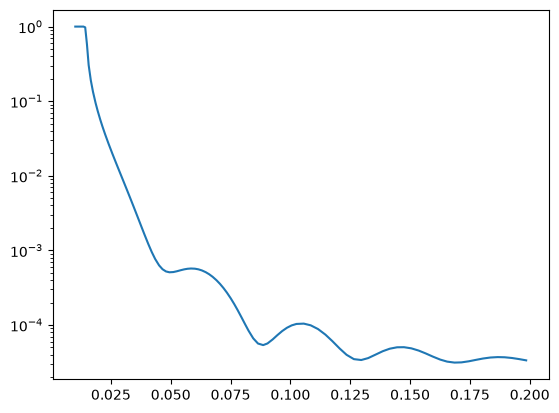

In [5]:
# `CompiledModel.model` calculates the forward model.
# if you provide data.x_err you get a resolution smeared version
# if you omit the last argument there's no resolution smearing.
y = cm.model(data.x, vp0, data.x_err)
plt.plot(data.x, y)
plt.yscale("log")

# check that the JAX calculated model is the same as the 'normal' refnx calculation
np.testing.assert_allclose(y, model(data.x, vp0, x_err=data.x_err))

# Note: you can supply x and x_err arrays of arbitrary length. They don't have to come from a dataset
x = np.geomspace(0.01, 0.02, 1001)
x_err = 0.05 * x
print(cm.model(x, vp0, x_err).shape)

### Jacobian of the forward model

The jacobian is the partial derivative of the reflectivity with respect to each of the parameters.

In [6]:
# `CompiledModel.jacfwd` calculates the jacobian.
# For a model with N points and P free parameters the shape of the jacobian should be (N, P).
# For a given point N there are P partial derivatives.
# Here there are 99 data points and 8 free parameters.
jac = cm.jacfwd(data.x, vp0, data.x_err)
print(jac.shape)
assert cm.n_free == jac.shape[-1]

(99, 8)


In [7]:
# we can also differentiate the forward model ourselves.
# argnums says we want to be differentiating R w.r.t the parameters.
my_jac_fn = jax.jacobian(cm.model, argnums=1)
jac = my_jac_fn(data.x, vp0, data.x_err)
print(jac.shape)

(99, 8)


### Compare the jacobian to that estimated by numerical differentiation (scipy)

The values calculated by automatic differentiation are much more accurate

In [8]:
# For `model(x, vp0)` we need to freeze the x values to differentiate against vp0
pf = partial(model, data.x)

numdiff_jac = approx_derivative(pf, vp0)
np.testing.assert_allclose(numdiff_jac, jac, atol=4e-3)

## Differentiating the *Objective*

In [9]:
# co is a `CompiledObjective` object
co = compile_objective(objective)

In [10]:
# `CompiledObjective.logl` gives the log-likelihood of the objective.
# compare to the Objective.logl method.
co.logl(op0), objective.logl(op0)

(-9947.969085550589, np.float64(-9947.969085550589))

### Gradient of the log-likelihood

The gradient is the partial derivative of the log-likelihood with respect to each parameter

In [11]:
# `CompiledObjective.grad_logl` calculates the gradient
co.grad_logl(op0)

Array([-1.14727693e+04, -1.80130117e+08, -3.76506366e+02,  1.15378657e+01,
       -5.57974882e+01,  7.40853650e+03,  1.46276107e+02,  3.09656902e+02],      dtype=float64)

In [12]:
# compare to the numerical differentiation estimation with finite differences
np.testing.assert_allclose(
    co.grad_logl(op0), approx_derivative(objective.logl, op0)
)

### Hessian of the log-likelihood

The Hessian is the second derivative of the log-likelihood with respect to the parameters.

In [13]:
# all we have to do is differentiate the gradient (1st derivative)
hf = jax.jacobian(co.grad_logl)

In [14]:
hf(op0)

Array([[-2.31677175e+05, -1.68456565e+08, -1.01420995e+03,
         1.26722501e+01, -5.87856361e+01,  3.83798324e+04,
         3.28705698e+02,  9.84409993e+02],
       [-1.68456565e+08, -1.12059446e+13, -2.37351844e+06,
         1.48737126e+06, -1.78760615e+05,  7.18908123e+07,
         3.22103182e+06,  1.15841270e+07],
       [-1.01420995e+03, -2.37351844e+06, -1.41251771e+01,
         5.02327915e+00, -6.12128839e+00,  3.59284421e+02,
         6.46745496e+00,  1.22657895e+01],
       [ 1.26722501e+01,  1.48737126e+06,  5.02327915e+00,
        -3.02591352e-02, -3.11646538e-01,  7.77133537e+00,
        -1.16960227e+00, -2.23245197e+00],
       [-5.87856361e+01, -1.78760615e+05, -6.12128839e+00,
        -3.11646538e-01,  2.22194091e+00, -4.38056902e-01,
         1.25482930e+00,  2.50834452e+00],
       [ 3.83798324e+04,  7.18908123e+07,  3.59284421e+02,
         7.77133537e+00, -4.38056902e-01, -1.34835815e+04,
        -1.90679294e+02, -4.22490141e+02],
       [ 3.28705698e+02,  3.221031

In [15]:
# compare to the hessian calculated by numerical differentiation
np.testing.assert_allclose(
    hf(op0), approx_derivative(co.grad_logl, op0), rtol=5e-7
)

## Setting up a `pymc` Model with a `Generative`

The `to_pymc_model` convenience function can create a `pymc.Model` for carrying out inference with [`pymc`](https://www.pymc.io/#). An example with co-refining several datasets is given [here](https://refnx.readthedocs.io/en/latest/pymc_lipid_sampling.html).

Here we're going to be explicit and show how you can use pymc functionality directly, in case you wish to adapt it for your own purposes. An example might be to model Poissonian counting statistics.

In [16]:
import pymc as pm

# this GenerativeOp wraps up jax code into a Pytensor that pymc can use.
from refnx.reflect.extra import GenerativeOp
import pytensor
import pytensor.tensor as pt
import arviz as az

In [17]:
fitter = CurveFitter(objective)
fitter.fit("differential_evolution", verbose=False);

In [18]:
with pm.Model() as model:
    pars = objective.parameters.varying_parameters()
    wrapped_pars = []

    # we gave all the parameters a uniform prior
    # if you wish you could give a different type of distribution. pymc has many kinds of inbuilt distributions.
    for i, p in enumerate(pars):
        _p = pm.Uniform(f"p{i}", p.bounds.lb, p.bounds.ub, initval=p.value)
        wrapped_pars.append(_p)
    theta = tuple(wrapped_pars)

    # co is our CompiledObjective
    # we want to make a Pytensor out of `co.generative`, which is a JAX function.
    gen_op = GenerativeOp(co)
    R_model = pm.Deterministic("R_model", gen_op(theta))

    # alternatively we can wrap the JAX function from our CompiledObjective:
    # R_model = pm.Deterministic(
    #     "R_model",
    #     pytensor.wrap_jax(co.generative)(pt.stack(theta))
    # )

    # the following is setting up a Normally distributed epsilon on each fitted point.
    # the mean value is assumed to be the generative model, the observed data are the data.y values
    # and the uncertainties on the observed data is given by data.y_err.
    pm.Normal(
        "y_obs",
        mu=R_model,
        sigma=data.y_err,
        observed=data.y,
    )
    idata = pm.sample()

NUTS[nutpie]: [p0, p1, p2, p3, p4, p5, p6, p7]
/Users/andrew/miniforge3/envs/test/lib/python3.14/site-packages/pytensor/link/numba/dispatch/basic.py:234: UserWarning: Numba will use object mode to run GenerativeOp's perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
/Users/andrew/miniforge3/envs/test/lib/python3.14/site-packages/pytensor/link/numba/dispatch/basic.py:234: UserWarning: Numba will use object mode to run _GenerativeVJPOp's perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
/Users/andrew/miniforge3/envs/test/lib/python3.14/site-packages/pytensor/link/numba/dispatch/basic.py:234: UserWarning: Numba will use object mode to run GenerativeOp's perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(


Output()

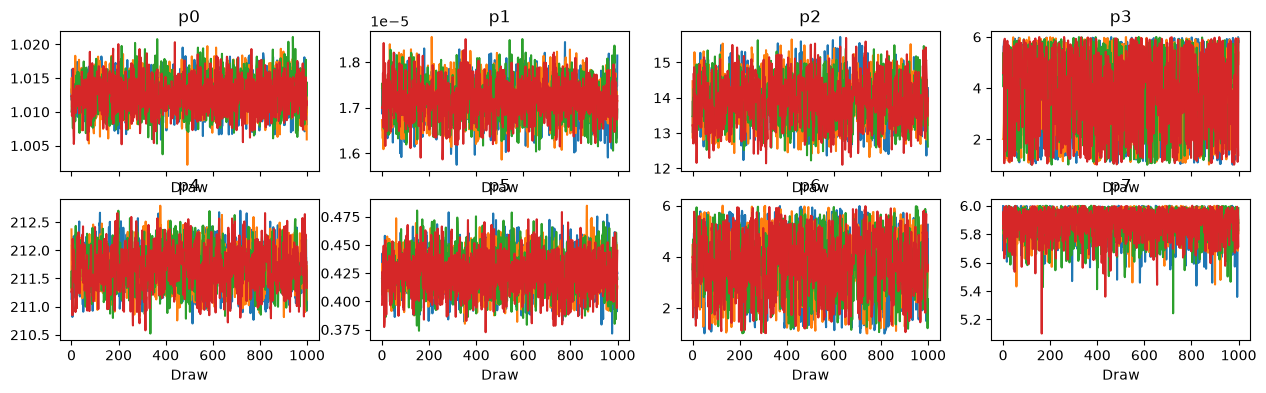

In [19]:
# The arviz package can display the traces for all the varying parameters.
# p0, p1, p2, ..., refer the the ordered list of varying parameters in the system.
az.plot_trace(idata, var_names=["p"], filter_vars="like");